# Assignment 2.2 — Streaming Classification with a Buffered Decision Tree

**NumCompute | Individual assignment demonstration**

This notebook uses **only Python, NumPy, Matplotlib and our own `numcompute` / `numcompute_stream` code** for the algorithm and data pipeline. No pandas, scikit-learn or other machine-learning packages are used.

**What the notebook demonstrates:** reading CSV using `numcompute_stream.io` (which delegates to our group's `numcompute.io`), splitting into consecutive chunks, preprocessing incrementally, retraining **one decision tree** at buffer thresholds, scoring each chunk **before** learning from it, logging metrics, and plotting accuracy/error/AUC and predictions. A second *independent single tree* is used **only for the buffer-size comparison**, never as an ensemble.

**Important:** the warm-up chunks cannot be scored because no trained tree exists yet. Such metrics appear as `NaN`, not as zero; they are excluded from cumulative accuracy. The final incomplete buffer is not forcibly trained.


## 1. Setup and load data

Run this notebook with the Python interpreter used by VS Code for your repository. From the **repository root** (the directory containing `pyproject.toml`), run `python -m pip install -e .` and `python -m pip install -r requirements-dev.txt`. Ensure the VS Code **Python** and **Jupyter** extensions are installed; select the matching Python kernel.

The dataset is the existing `demo/data/titanic.csv`. We use five numeric features and the string target `survived`. Missing values in features are handled by our streaming imputer. We preserve the CSV row order to simulate an arriving stream; this is *not* a random train/test split.


In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from numcompute_stream.io import iter_supervised_csv
from numcompute_stream.preprocessing import Imputer, StandardScaler
from numcompute_stream.tree import DecisionTreeClassifier
from numcompute_stream.pipeline import Pipeline
from numcompute_stream.stream import StreamTrainer
from numcompute_stream.visualise import (
    LiveMetricPlot, plot_metric_over_time, compare_models,
    plot_predictions_vs_ground_truth, plot_stream_dashboard,
)

# VS Code may launch a notebook from the repository root or from demo/.
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'pyproject.toml').is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'pyproject.toml').is_file():
    raise RuntimeError('Open the notebook from the repository root or demo/ directory.')
DATA_PATH = PROJECT_ROOT / 'demo' / 'data' / 'titanic.csv'
OUTPUT_DIR = PROJECT_ROOT / 'demo' / 'outputs'
FEATURES = ['pclass', 'age', 'sibsp', 'parch', 'fare']
TARGET = 'survived'
CHUNK_SIZE = 100
print('CSV path:', DATA_PATH.relative_to(PROJECT_ROOT))
print('Feature columns:', FEATURES)
print('Target:', TARGET, '| chunk size:', CHUNK_SIZE)
assert DATA_PATH.is_file()

CSV path: demo\data\titanic.csv
Feature columns: ['pclass', 'age', 'sibsp', 'parch', 'fare']
Target: survived | chunk size: 100


In [2]:
preview_X, preview_y = next(iter_supervised_csv(
    DATA_PATH, target=TARGET, features=FEATURES, chunksize=CHUNK_SIZE))
print('First chunk X shape:', preview_X.shape, '| y shape:', preview_y.shape)
print('First chunk missing feature cells:', int(np.isnan(preview_X).sum()))
print('Target labels:', np.unique(preview_y).tolist())
print('First 3 rows of numeric X:')
print(preview_X[:3])

First chunk X shape: (100, 5) | y shape: (100,)
First chunk missing feature cells: 22
Target labels: ['0', '1']
First 3 rows of numeric X:
[[ 3.     22.      1.      0.      7.25  ]
 [ 1.     38.      1.      0.     71.2833]
 [ 3.     26.      0.      0.      7.925 ]]


## 2. Define the streaming pipelines

Both pipelines have the same preprocessing, depth, and split criterion; only `buffer_size` changes. **The main model is a single decision tree with `buffer_size=200`.** The challenger is another single tree with `buffer_size=100` for comparison. The tree retrains from scratch using the most recently collected buffer and then clears it. Our `Pipeline` freezes its inference-transform state between retrains.


In [3]:
def make_trainer(buffer_size):
    pipeline = Pipeline([
        ('impute', Imputer(strategy='mean')),
        ('scale', StandardScaler()),
        ('tree', DecisionTreeClassifier(max_depth=5, criterion='gini',
                                        buffer_size=buffer_size)),
    ])
    return StreamTrainer(pipeline, positive_label='1', window_size=200)

main_trainer = make_trainer(buffer_size=200)
comparison_trainer = make_trainer(buffer_size=100)
print('Main model buffer size:', main_trainer.model.buffer_size)
print('Comparison model buffer size:', comparison_trainer.model.buffer_size)

Main model buffer size: 200
Comparison model buffer size: 100


## 3. Process the stream: **predict first, train second**

The `StreamTrainer.fit_chunk(X, y)` call computes predictions using the previously trained tree, records metrics, then calls `.partial_fit()` once. No current chunk contributes to its own evaluation. We keep copies of the latest **pre-training predictions** for the predictions-versus-truth graph.

The `LiveMetricPlot` updates on each chunk. With a GUI Matplotlib backend it can redraw during streaming (`pause > 0`). The default VS Code inline notebook backend shows the final accumulated frame when the cell finishes; the printed chunk logs update during execution.


chunk  size  accuracy  cumulative     AUC  buffered retrains  update_ms
    1   100       N/A         N/A     N/A       100        0       0.28
    2   100       N/A         N/A     N/A         0        1      10.63
    3   100     0.560       0.560   0.528       100        1       0.21
    4   100     0.590       0.575   0.627         0        2      12.85
    5   100     0.690       0.613   0.644       100        2       0.21
    6   100     0.670       0.627   0.651         0        3       8.77
    7   100     0.720       0.646   0.666       100        3       0.28
    8   100     0.670       0.650   0.664         0        4       8.90
    9    91     0.692       0.656   0.682        91        4       0.39


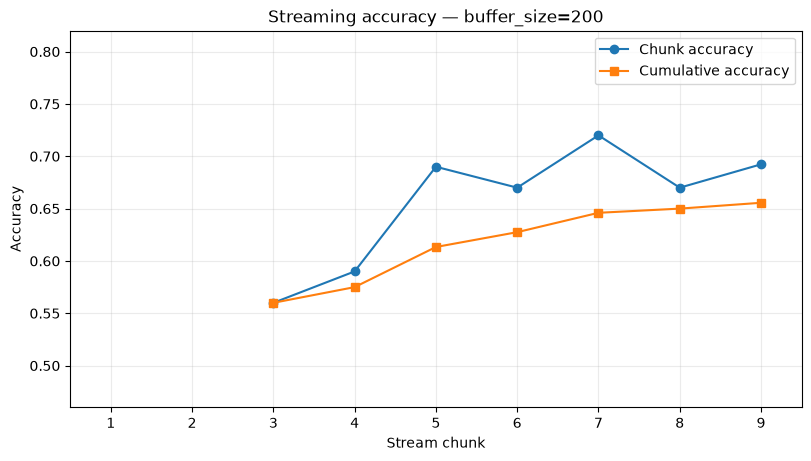

In [4]:
live = LiveMetricPlot(title='Streaming accuracy — buffer_size=200', pause=0)
latest_y_true, latest_y_pred = None, None

print(f"{'chunk':>5} {'size':>5} {'accuracy':>9} {'cumulative':>11} "
      f"{'AUC':>7} {'buffered':>9} {'retrains':>8} {'update_ms':>10}")
for X_chunk, y_chunk in iter_supervised_csv(
        DATA_PATH, target=TARGET, features=FEATURES, chunksize=CHUNK_SIZE):
    # Snapshot the prediction *before* fit_chunk uses the incoming samples.
    if main_trainer.model.is_fitted:
        latest_y_true = y_chunk.copy()
        latest_y_pred = main_trainer.model.predict(X_chunk).copy()

    row = main_trainer.fit_chunk(X_chunk, y_chunk)
    comparison_trainer.fit_chunk(X_chunk, y_chunk)
    live.update(row)

    def as_text(number):
        return 'N/A' if not np.isfinite(number) else f'{number:.3f}'

    print(f"{row['chunk']:5d} {row['n_samples']:5d} "
          f"{as_text(row['chunk_accuracy']):>9} "
          f"{as_text(row['cumulative_accuracy']):>11} "
          f"{as_text(row['auc']):>7} {row['buffered_samples']:9d} "
          f"{row['n_retrains']:8d} {row['update_ms']:10.2f}")

plt.show()

## 4. Review metrics and timing

The cumulative metrics exclude the warm-up period. The confusion matrix uses **rows = true labels** and **columns = predicted labels**. Training time is measured in milliseconds per `.partial_fit()` update; it is much larger at a buffer threshold because the entire tree is retrained.


In [5]:
summary = main_trainer.result()
print('Total samples:', summary['n_samples_seen'])
print('Warm-up samples:', summary['n_warmup_samples'])
print('Evaluated samples:', summary['support'])
print('Cumulative accuracy:', round(summary['accuracy'], 4))
print('Precision:', round(summary['precision'], 4),
      '| Recall:', round(summary['recall'], 4),
      '| F1:', round(summary['f1'], 4))
print('AUC:', round(summary['auc'], 4))
print('Retraining events:', summary['n_retrains'])
print('Remaining buffered samples:', summary['buffered_samples'])
print('Confusion matrix [rows=true, columns=predicted]:')
print(summary['confusion_matrix'])
print('Label order:', summary['labels'].tolist())

Total samples: 891
Warm-up samples: 200
Evaluated samples: 691
Cumulative accuracy: 0.6556
Precision: 0.6101 | Recall: 0.3553 | F1: 0.4491
AUC: 0.6823
Retraining events: 4
Remaining buffered samples: 91
Confusion matrix [rows=true, columns=predicted]:
[[356  62]
 [176  97]]
Label order: ['0', '1']


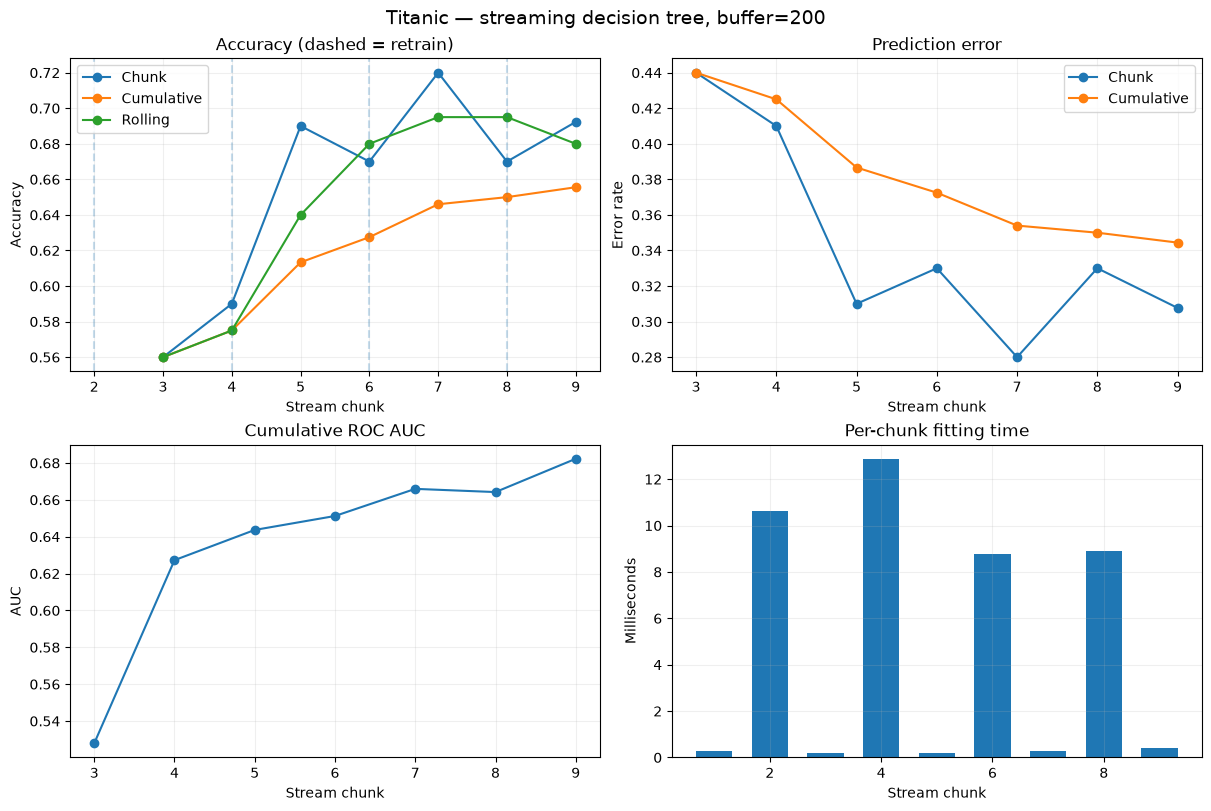

In [6]:
fig_dashboard, dashboard_axes = plot_stream_dashboard(
    main_trainer.history_, title='Titanic — streaming decision tree, buffer=200')
plt.show()

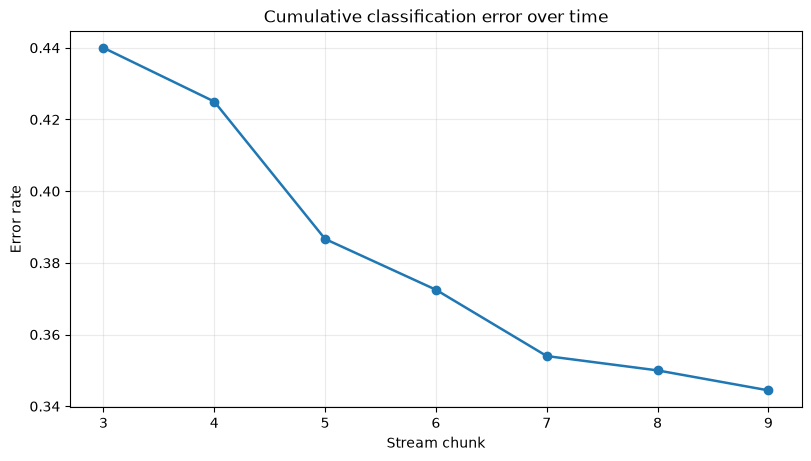

In [7]:
fig_error, ax_error = plot_metric_over_time(
    [row['cumulative_error'] for row in main_trainer.history_],
    title='Cumulative classification error over time', ylabel='Error rate')
plt.show()

## 5. Compare **buffer sizes** on the same evaluated chunks

Different buffer sizes train at different times. A tree with buffer 100 can predict after the first chunk, while a tree with buffer 200 can only predict after the second. Directly comparing their *overall cumulative accuracy* would use different evaluation populations. Instead, the graph below compares **per-chunk accuracy only where both models were already trained**, meaning both models are evaluated on exactly the same rows in each plotted chunk. This is a qualitative buffer-size comparison; controlled timing and accuracy benchmarks will be developed in Step 7.


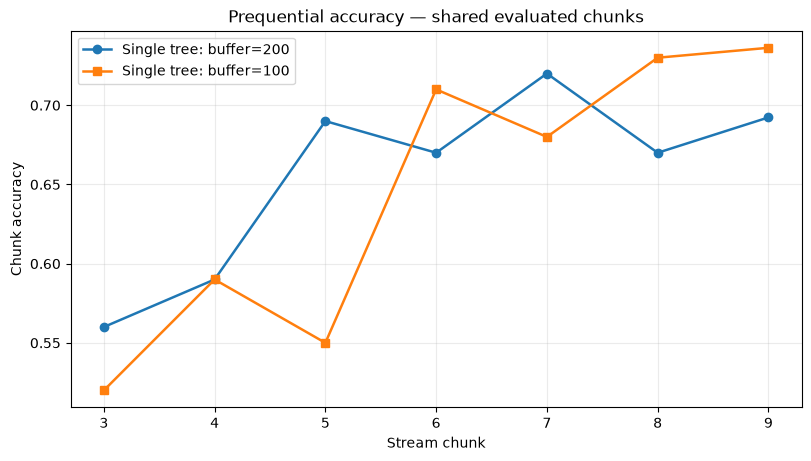

Shared evaluated chunks: [3, 4, 5, 6, 7, 8, 9]
Main retrains: 4 | Challenger retrains: 8


In [8]:
main_history = main_trainer.history_
other_history = comparison_trainer.history_
shared = [(a, b) for a, b in zip(main_history, other_history)
          if a['evaluated'] and b['evaluated']]
shared_chunk_ids = [a['chunk'] for a, b in shared]
main_accuracies = [a['chunk_accuracy'] for a, b in shared]
other_accuracies = [b['chunk_accuracy'] for a, b in shared]
assert len(shared_chunk_ids) > 0

fig_comparison, ax_comparison = compare_models(
    main_accuracies, other_accuracies,
    labels=['Single tree: buffer=200', 'Single tree: buffer=100'],
    chunk_indices=shared_chunk_ids,
    title='Prequential accuracy — shared evaluated chunks', ylabel='Chunk accuracy')
plt.show()

print('Shared evaluated chunks:', shared_chunk_ids)
print('Main retrains:', main_trainer.result()['n_retrains'],
      '| Challenger retrains:', comparison_trainer.result()['n_retrains'])

## 6. Predictions versus ground truth on the **latest evaluated chunk**

Actual and predicted labels are plotted separately for each arriving row. An `x` marks an error. These are predictions computed **before** the latest chunk was used for training.


Latest evaluated chunk: 91 rows
Accuracy before its training update: 0.6923


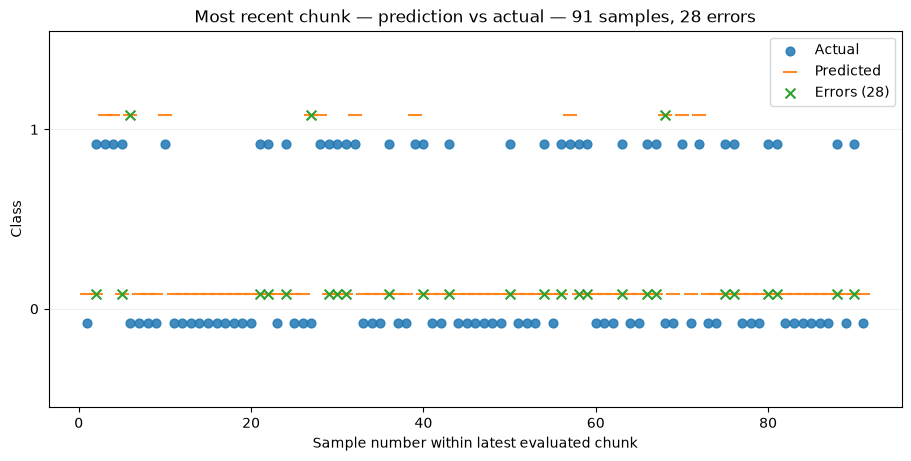

In [9]:
assert latest_y_true is not None and latest_y_pred is not None
latest_accuracy = float(np.mean(latest_y_true == latest_y_pred))
print('Latest evaluated chunk:', len(latest_y_true), 'rows')
print('Accuracy before its training update:', round(latest_accuracy, 4))
fig_predictions, ax_predictions = plot_predictions_vs_ground_truth(
    latest_y_true, latest_y_pred,
    title='Most recent chunk — prediction vs actual')
plt.show()

## 7. Export reusable plots

The `visualise.py` functions support in-notebook figures and PNG output. Images are saved under `demo/outputs/` (ignored by Git by default), so results can be reused in the four-page report or the five-minute demonstration video.


In [10]:
OUTPUT_DIR.mkdir(exist_ok=True, parents=True)
fig_dashboard.savefig(OUTPUT_DIR / 'stream_dashboard.png', dpi=160, bbox_inches='tight')
fig_error.savefig(OUTPUT_DIR / 'cumulative_error.png', dpi=160, bbox_inches='tight')
fig_comparison.savefig(OUTPUT_DIR / 'buffer_size_comparison.png', dpi=160, bbox_inches='tight')
fig_predictions.savefig(OUTPUT_DIR / 'latest_predictions.png', dpi=160, bbox_inches='tight')
live.save(OUTPUT_DIR / 'live_accuracy.png')
for path in sorted(OUTPUT_DIR.glob('*.png')):
    print(path.relative_to(PROJECT_ROOT))

demo\outputs\buffer_size_comparison.png
demo\outputs\cumulative_error.png
demo\outputs\latest_predictions.png
demo\outputs\live_accuracy.png
demo\outputs\stream_dashboard.png


## 8. Discussion and limitations

- **Algorithm:** One depth-limited, Gini-based decision tree per pipeline; no scikit-learn and no ensemble. Split search uses NumPy vectorisation. Each retrain replaces the previous tree using only the current buffered rows.
- **Streaming:** The custom CSV iterator yields 100 rows at a time. We test before training, avoid target leakage, and count warm-up data separately.
- **Drift / buffer size:** A smaller buffer retrains more frequently, potentially adapting faster but using fewer rows per replacement. Compare accuracy and timing experimentally; do not assume either configuration is universally better.
- **Data limitations:** Titanic rows are treated in CSV order as a *simulated* stream, not as a real temporal sequence. Features are limited to five numeric fields; some relevant categorical predictors are excluded in this demonstration.
- **Interpretation:** Training accuracy of the most recently rebuilt tree is not an evaluation measure. Streaming results are from unseen arriving chunks. Exact AUC accumulates scored pairs in memory, a tradeoff to discuss in the technical report.

